In [3]:
from typing import TypedDict, Literal
from pydantic import BaseModel
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
load_dotenv()  # Load environment variables from .env file

True

In [4]:
class State(TypedDict):
    request: str
    draft: str
    feedback: str
    approved: bool
    iterations: int

class Review(BaseModel):
    approved: bool
    feedback: str   # what to fix, empty if approved

In [5]:
llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0,
    max_tokens=500, # type: ignore
    timeout=30,
    max_retries=2,
)

In [ ]:
# 1. Generator: uses the critic's feedback when it exists
def generate(state: State):
    prompt = f"Write a short follow-up email: {state['request']}"
    if state.get("feedback"):
        prompt += (
            f"\n\nYour previous draft:\n{state['draft']}"
            f"\n\nFix these issues:\n{state['feedback']}"
        )
    draft = llm.invoke(prompt).content
    return {"draft": draft, "iterations": state.get("iterations", 0) + 1}

# 2. Critic: judges the draft against explicit criteria
def critique(state: State):
    review = llm.with_structured_output(Review).invoke(
        "Review this email. Approve only if ALL are true:\n"
        "- under 80 words\n- contains one clear ask\n- polite, not pushy\n\n"
        f"Email:\n{state['draft']}"
    )
    return {"approved": review.approved, "feedback": review.feedback} # type: ignore

# 3. Router: loop back, or stop
def should_continue(state: State) -> Literal["generate", "__end__"]:
    if state["approved"] or state["iterations"] >= 3:
        return END # type: ignore
    return "generate"

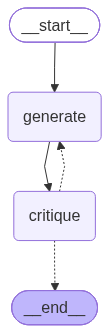

In [8]:
g = StateGraph(State)
g.add_node("generate", generate)
g.add_node("critique", critique)

g.add_edge(START, "generate")
g.add_edge("generate", "critique")
g.add_conditional_edges("critique", should_continue)

g.compile()

In [9]:
app = g.compile()

result = app.invoke({"request": "Ask a client for feedback on the proposal I sent last week"}) # type: ignore
print(result["draft"], "| rounds:", result["iterations"])

Subject: Follow-Up on Proposal

Hi [Client's Name],

I hope you’re doing well. I wanted to check in regarding the proposal I sent last week. I’d love to hear your thoughts and any feedback you may have.

Please let me know if you have any questions. 

Looking forward to your response!

Best,  
[Your Name]  
[Your Position]  
[Your Company]  
[Your Contact Information]   | rounds: 2
